# 5.2 EKF Localization

The Kalman filter (KF) is one of the best studied techniques for filtering and prediction of the state of linear systems. As any Bayes filter, it estimates the belief about the robot pose, $bel(\mathbf{x}_t) = p(\mathbf{x}_t | \mathbf{u}_{1:t}, \mathbf{z}_{1:t})$, through a recursive cycle: a **prediction** that propagates the previous belief using the motion model, and a **correction** that combines that prediction with the sensor likelihood using Bayes' rule. Among its virtues, it provides a way to overcome the occasional un-observability problem of the Least Squares approach, thanks to a model that predicts how the state changes. Nevertheless, it makes a strong assumption that the two involved process equations (state transition and observation) are linear:

$$\mathbf{x}_t = A_t\mathbf{x}_{t-1} + B_t\mathbf{u}_t + \boldsymbol{\varepsilon}_t, \qquad \mathbf{z}_t = C_t\mathbf{x}_t + \boldsymbol{\delta}_t$$

where $\boldsymbol{\varepsilon}_t \sim \mathcal{N}(\mathbf{0}, R_t)$ and $\boldsymbol{\delta}_t \sim \mathcal{N}(\mathbf{0}, Q_t)$ are the motion/process and measurement noises, respectively. That is, $R_t$ models the uncertainty of the motion and $Q_t$ that of the observations.

Unfortunately, you should already know that our system of measurements (i.e. the observation function) and motion (i.e. pose composition) are non-linear.
Therefore, this notebook focuses from the get-go on the **Extended Kalman Filter (EKF)**, which extends the KF to non-linear motion and measurement models:

$$\mathbf{x}_t = \mathbf{g}(\mathbf{x}_{t-1}, \mathbf{u}_t) + \boldsymbol{\varepsilon}_t, \qquad \mathbf{z}_t = \mathbf{h}(\mathbf{x}_t) + \boldsymbol{\delta}_t$$

by locally linearizing them and approximating the belief as Gaussian. When applied to robot localization, the EKF estimates the robot pose based on sensor measurements and a motion model, taking into account the noise in both the robot's motion and its sensors. Concretely, the robot pose $\mathbf{x}_t$ (its state) is modelled as a normal distribution, so $\mathbf{x}_t \sim \mathcal{N}(\boldsymbol{\mu}_t, \Sigma_t)$.

The EKF algorithm consists of 2 phases: **prediction** and **correction** (see Fig. 1):

$$
  \begin{aligned}
      \verb!def !& \verb!ExtendedKalmanFilter!(\boldsymbol{\mu}_{t-1},\Sigma_{t-1}, \mathbf{u}_t, \mathbf{z}_t): \\
      & \textbf{Prediction.} \\
      & \bar{\boldsymbol{\mu}}_t = \mathbf{g}(\boldsymbol{\mu}_{t-1}, \mathbf{u}_t) = \boldsymbol{\mu}_{t-1} \oplus \mathbf{u}_t &\text{(1. Pose prediction)}\\
      & \bar\Sigma_t = G_t \Sigma_{t-1} G_t^T + R_t &\text{(2. Uncertainty of prediction)}\\
      & \textbf{Correction.} \\
      & K_t = \bar\Sigma_t H^T_t (H_t \bar\Sigma_t H^T_t + Q_t)^{-1} &\text{(3. Kalman gain)}\\
      & \boldsymbol{\mu}_t = \bar{\boldsymbol{\mu}}_t + K_t (\mathbf{z}_t - \mathbf{h}(\bar{\boldsymbol{\mu}}_t)) &\text{(4. Pose estimation)}\\
      & \Sigma_t = (I - K_t H_t) \bar\Sigma_t &\text{(5. Uncertainty of estimation)}\\
      & \verb!return ! \boldsymbol{\mu}_t, \Sigma_t
  \end{aligned}
$$

Where:
  - $(\mathbf{u}_t, \Sigma_{\mathbf{u}_t})$ is the motion command received, and its respective uncertainty.
  - $(\mathbf{z}_t, Q_t)$ are the observations taken, and their covariance.
  - $G_t$ and $H_t$ are the Jacobians of the motion model and the observation model respectively:

$$G_t = \left.\frac{\partial \mathbf{g}(\mathbf{x}, \mathbf{u}_t)}{\partial \mathbf{x}}\right|_{\mathbf{x}=\boldsymbol{\mu}_{t-1}}, \qquad H_t = \left.\frac{\partial \mathbf{h}(\mathbf{x})}{\partial \mathbf{x}}\right|_{\mathbf{x}=\bar{\boldsymbol{\mu}}_t}$$

Notice that $R_t$ is the covariance of the motion/process uncertainty $\boldsymbol{\varepsilon}_t$. In our case it comes from the uncertainty $\Sigma_{\mathbf{u}_t}$ of the motion command $\mathbf{u}_t$, which is expressed in the robot frame, so it has to be propagated to the world frame:

$$R_t = J_2 \Sigma_{\mathbf{u}_t} J_2^T \quad\text{with}\quad J_2 = \left.\frac{\partial \mathbf{g}(\boldsymbol{\mu}_{t-1}, \mathbf{u})}{\partial \mathbf{u}}\right|_{\mathbf{u}=\mathbf{u}_t}$$

Note: $J_2$ is our popular Jacobian of the pose composition with respect to the motion command, while $G_t$ is the Jacobian $J_1$ with respect to the previous pose (see the robot motion chapter).

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-2-ekf-overview.gif" width="900" alt="">
  <figcaption>Fig. 1. One cycle of EKF localization. In the prediction, the pose is moved with the motion command $\mathbf{u}_t$ and its uncertainty grows. In the correction, the measurement $\mathbf{z}_t$ to the landmark $\mathbf{m}_i$ is compared with the one expected from the predicted pose, $\mathbf{h}(\bar{\boldsymbol{\mu}}_t)$ (the red cross shows where $\mathbf{z}_t$ would place the landmark if the robot were at $\bar{\boldsymbol{\mu}}_t$): the pose is corrected accordingly and its uncertainty shrinks. The bar on the left shows how the uncertainty grows and shrinks along the cycle.</figcaption>
</figure>


At this point the steps in the **prediction** phase are straightforward for us: the uncertainty increases, since the previous state uncertainty is propagated through the motion model and new motion/process uncertainty $R_t$ is added. But, what's the intuition behind the steps in the **correction** one?

3. **Kalman gain**  $K_t=\bar{\Sigma}_t H_t^T ( H_t \bar{\Sigma}_t H_t^T + Q_t)^{-1}$

    This equation determines how much the prediction should be adjusted based on the new measurement. The Kalman Gain $K_t$ balances the confidence in the prediction with the confidence in the measurement. A high Kalman Gain means the measurement is trusted more than the prediction, while a low Kalman Gain means the prediction is trusted more. If the measurement noise $Q_t$ is high, the gain will be low, meaning the model relies more on its prediction than on the noisy measurement. The term $H_t \bar{\Sigma}_t H_t^T + Q_t$ is the covariance of the innovation (see below).

   <figure style="text-align:center">
     <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-2-kalman-gain.png" width="750" alt="">
     <figcaption>Fig. 2. Kalman gain in a 1D example: the more precise the sensor (smaller $Q_t$), the larger $K_t$ and the more the posterior is pulled from the prior towards the likelihood of the measurement.</figcaption>
   </figure>

4. **Pose estimation** $\boldsymbol{\mu}_t = \bar{\boldsymbol{\mu}}_t + K_t(\mathbf{z}_t-\mathbf{h}(\bar{\boldsymbol{\mu}}_t))$

    This step updates the current state estimate (pose) $\boldsymbol{\mu}_t$ using the Kalman gain from the previous step and the difference between the observed measurement $\mathbf{z}_t$ and the predicted measurement $\mathbf{h}(\bar{\boldsymbol{\mu}}_t)$. The term $(\mathbf{z}_t-\mathbf{h}(\bar{\boldsymbol{\mu}}_t))$ is called the **innovation** or **measurement residual**. It represents the discrepancy between the predicted measurement (based on the current state estimate) and the actual measurement. The innovation provides information on how far off the prediction was. If the innovation is small, the predicted state is close to the actual state; if it’s large, there’s a significant discrepancy that needs correction. This update moves the estimated pose closer to the observed measurement while accounting for the predicted state and measurement uncertainties.

   <figure style="text-align:center">
     <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-2-pose-estimation.png" width="750" alt="">
     <figcaption>Fig. 3. Pose estimation in a 1D example: the innovation, computed in the measurement space, is scaled by $K_t$ into a correction of the pose, in the state space.</figcaption>
   </figure>

5. **Uncertainty of the estimation** $\Sigma_t = (I-K_t H_t) \bar{\Sigma}_t$

    This equation updates the covariance matrix $\Sigma_t$, representing the uncertainty in the state estimate after incorporating the measurement. It reduces the uncertainty in the state estimate based on the Kalman Gain (the correction does not increase the predicted covariance). If the Kalman Gain is high (i.e., the measurement is reliable), the uncertainty is reduced significantly. If the Kalman Gain is low (i.e., the measurement is less reliable), the reduction in uncertainty is smaller. This adaptability helps maintain a realistic assessment of the confidence in the state estimate.

   <figure style="text-align:center">
     <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-2-uncertainty.png" width="750" alt="">
     <figcaption>Fig. 4. Uncertainty of the estimation in a 1D example: the correction always reduces the uncertainty, and the larger $K_t$, the larger the reduction.</figcaption>
   </figure>

In this notebook we are going to play with the EKF localization algorithm using a map of landmarks and a sensor providing range and bearing measurements from the robot pose to such landmarks. Concretely, **we are going to**:
1. Implement a class modeling a **range and bearing sensor** able to take measurements to landmarks.
2. Complete a class that implements the robot behavior after completing **motion commands**.
3. Implement the **Jacobian of the observation model**.
4. With the previous building blocks, implement our own **EKF filter** and see it in action.
5. Finally, we are going to consider a more **realistic sensor** with a given Field of View and a maximum operational range.

In [1]:
# In case of using Google Colab, mount Google Drive and enable interactive plots
try:
    from google.colab import drive, output
    drive.mount('/content/drive')
    # Change directory to this chapter's folder in your Drive copy of the course repo:
    %cd '/content/drive/MyDrive/Colab Notebooks/uma_robotics_2027/Chapter 05. Localization'
    %pip install -q ipympl
    # Make matplotlib detect the freshly installed ipympl backend:
    from matplotlib.backends.registry import backend_registry
    backend_registry.__init__()
    output.enable_custom_widget_manager()
except ImportError:
    pass

%matplotlib widget

# IMPORTS
import numpy as np
from numpy import random
from numpy import linalg
from matplotlib import pyplot as plt
from IPython.display import display, clear_output
import time
import ipywidgets as widgets

import sys
sys.path.append("..")
from utils.AngleWrap import AngleWrapList
from utils.PlotEllipse import PlotEllipse
from utils.Drawings import DrawRobot, drawFOV, drawObservations
from utils.Jacobians import J1, J2
from utils.tcomp import tcomp

### **<span style="color:green"><b><i>ASSIGNMENT 1: Getting an observation to a random landmark</i></b></span>**


We are going to implement the `Sensor()` class modelling a range and bearing sensor. Recall that the observation model of this type of sensors is:

$$
\mathbf{z}_i= \begin{bmatrix} d_i \\ \theta_i \end{bmatrix}=\mathbf{h}(\mathbf{x},\mathbf{m}_i) + \mathbf{e}_i=
\begin{bmatrix} \sqrt{(x_i-x)^2+(y_i-y)^2} \\ \text{atan2}(y_i-y,\, x_i-x) - \theta \end{bmatrix}+\mathbf{e}_i
$$

where $\mathbf{m}_i=[x_i,y_i]^T$ are the landmark coordinates in the world frame, $\mathbf{x}=[x,y,\theta]^T$ is the robot pose, and the sensor error $\mathbf{e}_i = [e_{d_i}, e_{\theta_i}]^T$ follows a Gaussian distribution with zero mean and covariance matrix:

$$Q =
    \begin{bmatrix}
        \sigma^2_d & 0 \\
        0 & \sigma^2_{\theta}
    \end{bmatrix}
$$

For that, complete the following methods:
- `observe()`: which, given a real robot pose (`from_pose`), returns the measurements to the landmarks in the map (`world`). If `noisy=true`, then a random Gaussian noise with zero mean and covariance $Q$ (`cov`) is added to each measurement. *Hint: you can use [`random.randn()`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.randn.html) for that.*

- `random_observation()`: that, given again the robot pose (`from_pose`), randomly selects a landmark from the map (`world`) and returns an observation from the range-bearing sensor using the `observe()` method previously implemented. The `noisy` argument is just passed to `observe()`.  *Hint: to randomly select a landmark, use [`randint()`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.randint.html).*

In [2]:
class Sensor():
    def __init__(self, cov):
        """
        Args:
            cov: covariance of the sensor.
        """
        self.cov = cov

    def observe(self, from_pose, world, noisy=True, flatten=True):
        """Calculate observation relative to from_pose

        Args:
            from_pose: Position(real) of the robot which takes the observation
            world: List of world coordinates of some landmarks
            noisy: Flag, if true then add noise (Exercise 2)

        Returns:
                Numpy array of polar coordinates of landmarks from the perspective of our robot
                They are organised in a vertical vector z = [d_1, theta_1, d_2, ..., theta_n]^T
                Dims (2*n_landmarks, 1)
        """
        delta = world - from_pose[0:2]

        z = np.empty_like(delta)
        z[0, :] = np.sqrt(delta[0, :]**2 + delta[1, :]**2)
        z[1, :] = np.arctan2(delta[1, :], delta[0, :]) - from_pose[2, 0]
        z[1, :] = AngleWrapList(z[1, :])

        if noisy:
            z += np.sqrt(self.cov)@random.randn(2, world.shape[1])

        if flatten:
            return np.vstack(z.flatten('F'))
        else:
            return z

    def random_observation(self, from_pose, world, noisy=True):
        """ Get an observation from a random landmark

            Args: Same as observe().

            Returns:
                z: Numpy array of obs. in polar coordinates
                landmark: Index of the randomly selected landmark in the world map
                    Although it is only one index, you should return it as
                    a numpy array.
        """
        n_landmarks = world.shape[1]
        rand_idx = random.randint(0, n_landmarks)
        world = world[:, [rand_idx]]

        z = self.observe(from_pose, world, noisy)

        return z, np.array([rand_idx])

You can use the code cell below **to test your implementation**.

In [3]:
# TRY IT!
seed = 0
np.random.seed(seed)

# Sensor characterization
SigmaR = 1 # Standard deviation of the range
SigmaB = 0.7 # Standard deviation of the bearing
Q = np.diag([SigmaR**2, SigmaB**2]) # Cov matrix of the sensor (Q)

sensor = Sensor(Q)

# Map
Size = 50.0
NumLandmarks = 3
Map = Size*2*random.rand(2,NumLandmarks)-Size

# Robot true pose
true_pose = np.vstack([-Size+Size/3, -Size+Size/3, np.pi/2])

# Take a random measurement
noisy = False
z = sensor.random_observation(true_pose, Map, noisy)

noisy = True
noisy_z = sensor.random_observation(true_pose, Map, noisy)

# Take observations to every landmark in the map
zs = sensor.observe(true_pose, Map, noisy)

print('Measurement:\n' + str(z))
print('Noisy measurement:\n' + str(noisy_z))
print('Measurements to every landmark in the map:\n' + str(zs))

Measurement:
(array([[53.76652662],
       [-0.79056712]]), array([0]))
Noisy measurement:
(array([[64.73997127],
       [-0.81342958]]), array([2]))
Measurements to every landmark in the map:
[[ 5.51319938e+01]
 [-1.10770618e+00]
 [ 6.04762304e+01]
 [-1.46219661e+00]
 [ 6.23690518e+01]
 [-5.72010701e-02]]


<span style="color:blue">Expected output</span>

```
Measurement:
(array([[53.76652662],
       [-0.79056712]]), array([0]))
Noisy measurement:
(array([[64.73997127],
       [-0.81342958]]), array([2]))
Measurements to every landmark in the map:
[[ 5.51319938e+01]
 [-1.10770618e+00]
 [ 6.04762304e+01]
 [-1.46219661e+00]
 [ 6.23690518e+01]
 [-5.72010701e-02]]
 ```

### **<span style="color:green"><b><i>ASSIGNMENT 2: Simulating the robot motion</i></b></span>**
In the robot motion chapter we commanded a mobile robot to follow a squared trajectory. We provide here the `Robot` class that implements:
- how the robot pose evolves after executing a motion command (`step()` method), and
- the functionality needed to graphically show its ideal pose (`pose`), true pose (`true_pose`) and estimated pose (`xEst`) in the `draw()` function.

Your mission is to complete the `step()` method by adding random noise to each motion command $\mathbf{u}_t$ (`noisy_u`) based on the following covariance matrix (`cov_move`), and update the true robot pose (`true_pose`):

$$\Sigma_{\mathbf{u}_t} =
    \begin{bmatrix}
        \sigma^2_{\Delta x} & 0 & 0\\
        0 & \sigma^2_{\Delta y} & 0\\
        0 & 0 & \sigma^2_{\Delta \theta}
    \end{bmatrix}
$$

*Hint: Recall again the [`random.randn()`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.randn.html) function.*

In [4]:
class Robot():
    def __init__(self, true_pose, cov_move):
        # Robot description (Starts as perfectly known)
        self.pose = true_pose
        self.true_pose = true_pose
        self.cov_move = cov_move

        # Estimated pose and covariance
        self.xEst = true_pose
        self.PEst = np.zeros((3, 3))

    def step(self, u):
        self.pose = tcomp(self.pose,u) # New pose without noise
        noise = np.sqrt(self.cov_move)@random.randn(3,1) # Generate noise
        noisy_u = u + noise #  Apply noise to the control action
        self.true_pose = tcomp(self.true_pose, noisy_u) #  New noisy pose (real robot pose)

    def draw(self, fig, ax):
        DrawRobot(fig, ax, self.pose, color='r')
        DrawRobot(fig, ax, self.true_pose, color='b')
        DrawRobot(fig, ax, self.xEst, color='g')
        PlotEllipse(fig, ax, self.xEst, self.PEst, 4, color='g')

It is time **to test** your `step()` function!

In [5]:
# Robot base characterization
SigmaX = 0.8 # Standard deviation in the x axis
SigmaY = 0.8 # Standard deviation in the y axis
SigmaTheta = 0.1 # Standard deviation in the heading
R = np.diag([SigmaX**2, SigmaY**2, SigmaTheta**2]) # Cov matrix of the motion command (Sigma_u)

# Create the Robot object
true_pose = np.vstack([2,3,np.pi/2])
robot = Robot(true_pose, R)

# Perform a motion command
u = np.vstack([1,2,0])
np.random.seed(0)
robot.step(u)

print('robot.true_pose.T:' + str(robot.true_pose.T) + '\'')

robot.true_pose.T:[[-0.32012577  5.41124188  1.66867013]]'


<span style="color:blue">Expected output</span>

```
robot.true_pose.T:[[-0.32012577  5.41124188  1.66867013]]'
```

### **<span style="color:green"><b><i>ASSIGNMENT 3:  Jacobians of the observation model</i></b></span>**

Given that the position of the landmarks in the map is known, we can use this information in a Kalman filter, in our case an EKF. For that we need to implement the **Jacobians of the observation model**, as required by the correction step of the filter.

Implement the function `getObsJac()` that given:
- the predicted pose $\bar{\boldsymbol{\mu}}_t$ in the first step of the Kalman filter,
- a number of observed landmarks, and
- the map,

returns such Jacobian. Recall that, for each observation to a landmark:

$$
J_{\mathbf{h},\mathbf{x}} = \frac{\partial \mathbf{h}}{\partial \{x,y,\theta \}} =
\begin{bmatrix}
    -\frac{x_i - x}{\|\mathbf{m}_i - \mathbf{r}\|} & - \frac{y_i - y}{\|\mathbf{m}_i - \mathbf{r}\|} & 0 \\
    \frac{y_i - y}{\|\mathbf{m}_i - \mathbf{r}\|^2} & -\frac{x_i - x}{\|\mathbf{m}_i - \mathbf{r}\|^2} & -1
\end{bmatrix}_{2 \times 3}
$$

Recall that $\mathbf{m}_i = [x_i,y_i]^T$ is the position of the $i^{th}$ landmark in the map, $\mathbf{r} = [x,y]^T$ is the robot predicted position (from $\bar{\boldsymbol{\mu}}_t$, where the Jacobian is evaluated), and $\|\mathbf{m}_i - \mathbf{r}\|$ the distance from such predicted position to the landmark. This way, the resultant Jacobian dimensions are $(2 \times \#\text{observed landmarks},\ 3)$, that is, the Jacobians of the observations are stacked vertically to form the matrix $H_t$.

In [6]:
def getObsJac(xPred, lm, Map):
    """ Obtain the Jacobian for all observations.

        Args:
            xPred: Position of our robot at which Jac is evaluated.
            lm: Numpy array of observations to a number of landmarks (indexes in map)
            Map: Map containing the actual positions of the observations.

        Returns:
            jH: Jacobian matrix (2*n_landmarks, 3)
    """
    n_land = len(lm)
    jH = np.empty((2*n_land,3))

    for i in range(n_land):
        # Auxiliary variables
        dx = Map[0, lm[i]] - xPred[0, 0]
        dy = Map[1, lm[i]] - xPred[1, 0]
        d = np.sqrt(dx**2 + dy**2)
        d2 = d**2

        ii = 2*i

        # Build the Jacobian
        jH[ii:ii+2,:] = [
            [-dx/d, -dy/d, 0],
            [dy/d2, -dx/d2, -1]
        ]

    return jH

Time **to check** your function!

In [7]:
# TRY IT!

observed_landmarks = np.array([0,2])
xPred = np.vstack([-Size+Size/3, -Size+Size/3, np.pi/2]) # Robot predicted pose
jH = getObsJac(xPred, observed_landmarks, Map) # Retrieve the evaluated observation jacobian

print ('Jacobian dimensions: ' + str(jH.shape) )
print ('jH:' + str(jH))

Jacobian dimensions: (4, 3)
jH:[[-0.71075232 -0.70344235  0.        ]
 [ 0.01308328 -0.01321923 -1.        ]
 [-0.67304061 -0.73960552  0.        ]
 [ 0.01141455 -0.01038723 -1.        ]]


<span style="color:blue">Expected output:</span>

```
Jacobian dimensions: (4, 3)
jH:[[-0.71075232 -0.70344235  0.        ]
 [ 0.01308328 -0.01321923 -1.        ]
 [-0.67304061 -0.73960552  0.        ]
 [ 0.01141455 -0.01038723 -1.        ]]
```

### **<span style="color:green"><b><i>ASSIGNMENT 4: Completing the EKF</i></b></span>**

Congratulations! You now have all the building blocks needed to implement an EKF filter (both prediction and correction steps) for localizing the robot and show the estimated pose and its uncertainty.

For doing that, complete the `EKFLocalization()` function below, which returns:
- the estimated pose (`xEst`, that is, $\boldsymbol{\mu}_t$), and
- its associated uncertainty (`PEst`, that is, $\Sigma_t$),

given:
- the previous estimations (`self.xEst` and `self.PEst` stored in `robot`, that is, $\boldsymbol{\mu}_{t-1}$ and $\Sigma_{t-1}$),
- the features of the sensor (`sensor`),
- the motion command provided to the robot (`u`, that is, $\mathbf{u}_t$),
- the observations done (`z`, that is, $\mathbf{z}_t$),
- the indices of the observed landmarks (`landmark`), and
- the map of the environment (`Map`).

The predicted pose and its uncertainty, $\bar{\boldsymbol{\mu}}_t$ and $\bar{\Sigma}_t$, are stored in `xPred` and `PPred`. Notice that, when several landmarks are observed at once, $\mathbf{z}_t$ stacks their observations and $Q_t$ is a block diagonal matrix with one sensor covariance $Q$ per observed landmark.

In [8]:
def EKFLocalization(robot, sensor, u, z, landmark, Map):
    """ Implement the EKF algorithm for localization

        Args:
            robot: Robot base (contains the state: xEst and PEst)
            sensor: Sensor of our robot.
            u: Motion command (u_t)
            z: Observations received (z_t)
            landmark: Indices of landmarks observed in z
            Map: Array with landmark coordinates in the map

        Returns:
            xEst: New estimated pose (mu_t)
            PEst: Covariance of the estimated pose (Sigma_t)
    """

    # Prediction (mu_bar_t and Sigma_bar_t)
    xPred = tcomp(robot.xEst, u)
    G = J1(robot.xEst, u)
    j2 = J2(robot.xEst, u)
    PPred = G@robot.PEst@G.T + j2@robot.cov_move@j2.T

    # Correction (You need to compute the Kalman gain K_t and the innovation z_t - h(mu_bar_t))
    if landmark.shape[0] > 0:
        H = getObsJac(xPred, landmark, Map) # Observation Jacobian H_t
        Q_t = np.kron(np.eye(landmark.shape[0]), sensor.cov) # Block diagonal: one Q per observed landmark
        K = PPred@H.T@linalg.inv(H@PPred@H.T + Q_t)

        innovation = z - sensor.observe(xPred, Map[:, landmark], noisy=False)
        innovation[1::2] = AngleWrapList(innovation[1::2]) # A difference of bearings can fall outside [-pi, pi]

        xEst = xPred + K@innovation # New estimated pose
        PEst = (np.eye(3) - K@H)@PPred # Covariance of the new estimated pose
    else:
        xEst = xPred
        PEst = PPred

    return xEst, PEst

You can **validate your code** with the code cell below.

In [9]:
# TRY IT!

np.random.seed(2)

# Create the map
Map=Size*2*random.rand(2,20)-Size

# Create the Robot object
true_pose = np.vstack([2,3,0])
R = np.diag([0.1**2, 0.1**2, 0.01**2]) # Cov matrix
robot = Robot(true_pose, R)

# Perform a motion command
u = np.vstack([10,0,0])
robot.step(u)

# Get an observation to a landmark
noisy = True
noisy_z, landmark_index = sensor.random_observation(true_pose, Map, noisy)

# Estimate the new robot pose using EKF!
robot.xEst, robot.PEst = EKFLocalization(robot, sensor, u, noisy_z, landmark_index, Map)

# Show results!
print('robot.pose.T:' + str(robot.pose.T) + '\'')
print('robot.true_pose.T:' + str(robot.true_pose.T) + '\'')
print('robot.xEst.T:' + str(robot.xEst.T) + '\'')
print('robot.PEst:' + str(robot.PEst.T))

robot.pose.T:[[12.  3.  0.]]'
robot.true_pose.T:[[ 1.20000010e+01  3.05423526e+00 -3.13508197e-03]]'
robot.xEst.T:[[ 1.19586407e+01  2.96047951e+00 -1.48514185e-04]]'
robot.PEst:[[ 9.94877200e-03 -4.94253023e-05 -3.18283546e-08]
 [-4.94253023e-05  9.95211532e-03  3.29230513e-08]
 [-3.18283546e-08  3.29230513e-08  9.99795962e-05]]


<span style="color:blue">Expected output:</span>
```
robot.pose.T:[[12.  3.  0.]]'
robot.true_pose.T:[[ 1.20000010e+01  3.05423526e+00 -3.13508197e-03]]'
robot.xEst.T:[[ 1.19586407e+01  2.96047951e+00 -1.48514185e-04]]'
robot.PEst:[[ 9.94877200e-03 -4.94253023e-05 -3.18283546e-08]
 [-4.94253023e-05  9.95211532e-03  3.29230513e-08]
 [-3.18283546e-08  3.29230513e-08  9.99795962e-05]]
```

## Playing with EKF

The following code helps you to see the EKF filter in action! With `visualization = 'non_stop'` the robot moves on its own, while with `visualization = 'step_by_step'` you have to press the **Next step** button to send each motion command to the robot. In both cases, check how the landmark it observes changes, as well as its ideal, true and estimated poses.

**Notice that** you can change the value of `seed` within the `main()` function to try different executions.

**Example**

The figure below shows an example of the execution of the EKF localization algorithm with the code implemented until this point.

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-2-1.png" width="500" alt="">
  <figcaption>Fig. 5. Execution of the EKF algorithm for localization, it shows the true (in blue) and ideal (in red) poses, along the results from localization: pose and ellipse (in green), the existing landmarks (in cyan), and each observation made (dotted lines).</figcaption>
</figure>

In [10]:
def main(robot,
         sensor,
         mode='one_landmark',
         visualization = 'non_stop',
         nSteps=20, # Number of motions
         turning=5, # Number of motions before turning (square path)
         Size=50.0,
         NumLandmarks=10,
         delay=0.2): # Wait time between motions in 'non_stop' mode

    seed = 1
    np.random.seed(seed)

    #Create map
    Map=Size*2*random.rand(2,NumLandmarks)-Size

    # MATPLOTLIB
    fig, ax = plt.subplots()
    plt.plot(Map[0,:],Map[1,:],'sc')
    plt.axis([-Size-15, Size+15, -Size-15, Size+15])
    plt.title(mode)

    robot.draw(fig, ax)
    plt.close(fig) # The figure is shown with display() after each motion

    u = np.vstack([(2*Size-2*Size/3)/turning,0,0]) # control action

    def move_and_localize(k):
        """ Performs the k-th motion command, localizes the robot with EKF and shows the result """
        u[2] = 0
        if k % turning == turning-1: # Turn?
            u[2] = -np.pi/2

        robot.step(u)

        # Get sensor observation/s
        if mode == 'one_landmark':
            # DONE (Exercise 4)
            z, landmark = sensor.random_observation(robot.true_pose, Map)
            ax.plot(
                [robot.true_pose[0,0], Map[0,landmark][0]],
                [robot.true_pose[1,0], Map[1,landmark][0]],
                color='m', linestyle="--", linewidth=.5)
        elif mode == 'landmarks_in_fov':
            # DONE (Exercise 5)
            z, landmark = sensor.observe_in_fov(robot.true_pose, Map)
            drawObservations(fig, ax, robot.true_pose, Map[:, landmark])

        robot.xEst, robot.PEst = EKFLocalization(robot, sensor, u, z, landmark, Map)

        # Drawings
        # Plot the FOV of the robot
        if mode == 'landmarks_in_fov':
            h = sensor.draw(fig, ax, robot.true_pose)
        #end

        robot.draw(fig, ax)
        clear_output(wait=True)
        display(fig)

        if mode == 'landmarks_in_fov':
            h.pop(0).remove()

    # MAIN LOOP

    if visualization == 'non_stop':
        display(fig)
        for k in range(0, nSteps-3):
            time.sleep(delay)
            move_and_localize(k)
    elif visualization == 'step_by_step':
        # Each click on the button sends a new motion command to the robot
        button = widgets.Button(description='Next step')
        out = widgets.Output()
        k = 0

        def on_click(b):
            nonlocal k
            with out:
                move_and_localize(k)
            k += 1
            button.disabled = k == nSteps-3 # No motions left

        button.on_click(on_click)
        display(button, out)
        with out:
            display(fig)

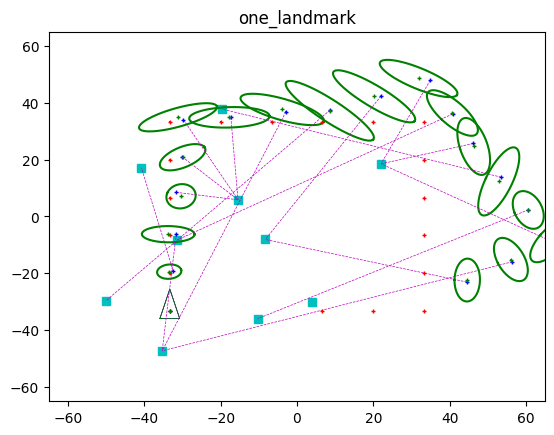

In [11]:
# RUN
mode = 'one_landmark'
# mode = 'landmarks_in_fov'
visualization = 'non_stop'
#visualization = 'step_by_step'

Size=50.0

# Robot base characterization
SigmaX = 0.8 # Standard deviation in the x axis
SigmaY = 0.8 # Standard deviation in the y axis
SigmaTheta = 0.1 # Standard deviation in the heading
R = np.diag([SigmaX**2, SigmaY**2, SigmaTheta**2]) # Cov matrix of the motion command (Sigma_u)

true_pose = np.vstack([-Size+Size/3, -Size+Size/3, np.pi/2])
robot = Robot(true_pose, R)

# Sensor characterization
SigmaR = 1 # Standard deviation of the range
SigmaB = 0.7 # Standard deviation of the bearing
Q = np.diag([SigmaR**2, SigmaB**2]) # Cov matrix of the sensor (Q)

sensor = Sensor(Q)

main(robot, sensor, mode=mode, visualization=visualization, Size=Size)
plt.close('all') # DrawRobot() calls plt.axis() after main() closed its figure, which opens an empty one


### **<span style="color:green"><b><i>ASSIGNMENT 5:  Implementing the FoV of a sensor.</i></b></span>**

Sensors exhibit certain physical limitations regarding their field of view (FoV) and maximum operating distance (max. range). Besides, these devices often do not deliver measurements from just one landmark each time, but from all those landmarks in the FoV.

The `FOVSensor()` class below extends the `Sensor()` one to implement this behaviour. Complete the `observe_in_fov()` method to consider that the sensor can only provide information from the landmarks in a limited range $r_l$ and a limited orientation $\pm \alpha$ with respect to the robot pose. For that:

1. Get the observations to every landmark in the map. Use the `observe()` function previously implemented for that, but with the argument `flatten=False`. With that option the function returns the measurements as:

   $$
   \mathbf{z} = \begin{bmatrix} d_1 &  \cdots &  d_m \\ \theta_1 & \cdots & \theta_m \end{bmatrix}
   $$

2. Check which observations lay in the sensor FoV and maximum operating distance. *Hint: for that, you can use the [`np.asarray()`](https://numpy.org/doc/stable/reference/generated/numpy.asarray.html) function with the conditions to be fulfilled by the valid measurements inside, and then filter the results with [`np.nonzero()`](https://numpy.org/doc/stable/reference/generated/numpy.nonzero.html)*.
3. Flatten the resultant matrix `z` to be again a vector, so it has the shape $(2 \times \#\text{observed landmarks},\ 1)$. *Hint: take a look at [`np.ndarray.flatten()`](https://numpy.org/doc/stable/reference/generated/numpy.ndarray.flatten.html) and choose the proper argument.*

Notice that it could happen that no landmark lies in the field of view of the sensor, so the robot couldn’t gather sensory information in that iteration. This, which is a problem using Least Squares Positioning, is not an issue with EKF. ***Hint: you can change the value of `seed` within the `main()` function to try different executions.***

In [12]:
class FOVSensor(Sensor):
    def __init__(self, cov, fov, max_range):
        super().__init__(cov)
        self.fov = fov
        self.max_range = max_range

    def observe_in_fov(self, from_pose, world, noisy=True):
        """ Get all observations in the fov

        Args:
            from_pose: Position(real) of the robot which takes the observation
            world: List of world coordinates of some landmarks
            noisy: Flag, if true then add noise (Exercise 2)

        Returns:
            Numpy array of polar coordinates of landmarks from the perspective of our robot
            They are organised in a vertical vector z = [d_1, theta_1, d_2, ..., theta_n]^T
            Dims (2*n_landmarks, 1)
        """
        # 1. Get observations to every landmark in the map WITHOUT NOISE
        z = self.observe(from_pose, world, False, False)

        # 2. Check which ones lay on the sensor FOV
        angle_limit = self.fov/2 # auxiliar variable
        feats_idx = np.nonzero(np.asarray((z[0, :] < self.max_range) & (np.abs(z[1, :]) < angle_limit)))[0] # indices of the valid observations

        if noisy:
            # 1. Get observations to every landmark in the map WITH NOISE
            z = self.observe(from_pose, world, True, False)

        z = z[:, feats_idx] # extracts the valid observations from z

        # 3. Flatten the  resultant vector of measurements so z=[d_1,theta_1,d_2,theta_2,...,d_n,theta_n]
        if z.size>0:
            z = np.vstack(z.flatten('F'))

        return z, feats_idx

    def draw(self, fig, ax, from_pose):
        """ Draws the Field of View of the sensor from the robot pose """
        return drawFOV(fig, ax, from_pose, self.fov, self.max_range)

You can now **try** your new and more realistic sensor.

z:[[1.17640523]
 [0.1867558 ]
 [1.84279136]
 [0.49027482]]


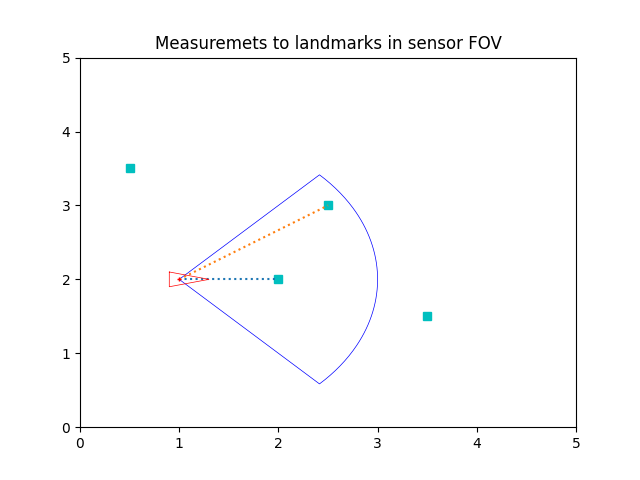

In [13]:
# TRY IT!
np.random.seed(0)

# Create the sensor object
cov = np.diag([0.1**2, 0.1**2]) # Cov matrix
fov = np.pi/2
max_range = 2
sensor = FOVSensor(cov, fov, max_range)

# Create a map with three landmarks
Map = np.array([[2., 2.5, 3.5, 0.5],[2., 3., 1.5, 3.5]])

# Take an observation of landmarks in FoV
robot_pose = np.vstack([1.,2.,0.])
z, feats_idx = sensor.observe_in_fov(robot_pose, Map)
print('z:' +str(z))

# Plot results
fig, ax = plt.subplots()
plt.axis([0, 5, 0, 5])
plt.title('Measuremets to landmarks in sensor FOV')
plt.plot(Map[0,:],Map[1,:],'sc')
sensor.draw(fig, ax, robot_pose)
drawObservations(fig, ax, robot_pose, Map[:, feats_idx])
DrawRobot(fig,ax,robot_pose)

<span style="color:blue">Expected output:</span>
    
```
z:[[1.17640523]
 [0.1867558 ]
 [1.84279136]
 [0.49027482]]
```    

## Playing with EKF and the new sensor

And finally, play with your own FULL implementation of the EKF filter with a more realistic sensor :)

**Example**

The figure below shows an example of the execution of EKF using information from all the landmarks within the FoV:

<figure style="text-align:center">
  <img src="https://raw.githubusercontent.com/jotaraul/robotics_hub/main/localization/images/fig5-2-2.png" width="500" alt="">
  <figcaption>Fig. 6. Execution of the EKF algorithm for localization. Same as in Fig. 5, except now our robot can observe every landmark in its FoV.</figcaption>
</figure>

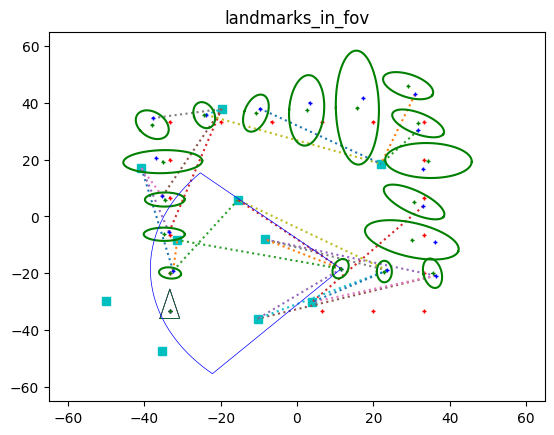

In [14]:
# RUN
#mode = 'one_landmark'
mode = 'landmarks_in_fov'
visualization = 'non_stop'
#visualization = 'step_by_step'
Size=50.0

# Robot base characterization
SigmaX = 0.8 # Standard deviation in the x axis
SigmaY = 0.8 # Standard deviation in the y axis
SigmaTheta = 0.1 # Standard deviation in the heading
R = np.diag([SigmaX**2, SigmaY**2, SigmaTheta**2]) # Cov matrix of the motion command (Sigma_u)

true_pose = np.vstack([-Size+Size/3, -Size+Size/3, np.pi/2])
robot = Robot(true_pose, R)

# Sensor characterization
SigmaR = 1 # Standard deviation of the range
SigmaB = 0.7 # Standard deviation of the bearing
Q = np.diag([SigmaR**2, SigmaB**2]) # Cov matrix of the sensor (Q)
fov = np.pi/2 # field of view = 2*alpha
max_range = Size # maximum sensor measurement range

sensor = FOVSensor(Q, fov, max_range)

main(robot, sensor, mode=mode, visualization=visualization, Size=Size)

## Comprobaciones y experimento añadidos

Estas celdas no las pide el enunciado. Comprueban el código por una vía independiente y dan los números con los que se responde a *Thinking about it*.

In [15]:
# Added checks
np.random.seed(0)

# 1. Observation Jacobian vs. numerical derivative (central differences)
sensor_check = Sensor(np.eye(2))
x_check = np.vstack([1., 2., 0.3])
map_check = np.array([[4., -2.], [6., 1.]])
H_analytic = getObsJac(x_check, np.array([0, 1]), map_check)
H_numeric = np.zeros((4, 3))
eps = 1e-6
for j in range(3):
    dx = np.zeros((3, 1))
    dx[j] = eps
    z_plus = sensor_check.observe(x_check + dx, map_check, noisy=False)
    z_minus = sensor_check.observe(x_check - dx, map_check, noisy=False)
    H_numeric[:, j] = ((z_plus - z_minus)/(2*eps)).ravel()
assert np.allclose(H_analytic, H_numeric, atol=1e-7)
print('Largest difference between getObsJac() and the numerical Jacobian:', np.abs(H_analytic - H_numeric).max())

# 2. Why the bearing of the innovation has to be wrapped: a landmark right behind the robot
pose = np.vstack([0., 0., 0.])
landmark_behind = np.array([[-10.], [0.05]])
z_pred = sensor_check.observe(pose, landmark_behind, noisy=False)
z_real = z_pred + np.vstack([0., 0.01]) # The sensor reads 0.01 rad more than expected...
z_real[1] = AngleWrapList(z_real[1]) # ...and, as any bearing, it is returned in [-pi, pi]
raw = (z_real - z_pred)[1, 0]
print(f'Predicted bearing {z_pred[1, 0]:.4f} rad, measured bearing {z_real[1, 0]:.4f} rad')
print(f'Innovation without wrapping: {raw:.4f} rad. Wrapped: {AngleWrapList(z_real - z_pred)[1, 0]:.4f} rad')


Largest difference between getObsJac() and the numerical Jacobian: 1.7816065289721905e-10
Predicted bearing 3.1366 rad, measured bearing -3.1366 rad
Innovation without wrapping: -6.2732 rad. Wrapped: 0.0100 rad


**Experimento: qué hace el filtro con cada sensor.** Repite la ejecución de `main()` (misma semilla, mapa y movimientos) guardando números en lugar de dibujar. Como medida de incertidumbre se usa $\sqrt{\mathrm{tr}(\Sigma_{xy})}=\sqrt{\sigma_x^2+\sigma_y^2}$, que es el error de posición que cabría esperar y se puede comparar directamente con el error real, en metros.

In [16]:
# Added experiment: the same run as main() (seed, map and motions), logging numbers instead of drawing
def simulate(mode, seed=1, max_range=50.0, Size=50.0, NumLandmarks=10, nSteps=20, turning=5):
    Sigma_u = np.diag([0.8**2, 0.8**2, 0.1**2])
    Q = np.diag([1**2, 0.7**2])
    robot = Robot(np.vstack([-Size+Size/3, -Size+Size/3, np.pi/2]), Sigma_u)
    sensor = FOVSensor(Q, np.pi/2, max_range) # It inherits random_observation() from Sensor

    np.random.seed(seed)
    Map = Size*2*random.rand(2, NumLandmarks) - Size
    u = np.vstack([(2*Size-2*Size/3)/turning, 0., 0.])

    log = {'n': [], 'e_ideal': [], 'e_est': [], 's_pred': [], 's_est': []}
    for k in range(nSteps-3):
        u[2] = -np.pi/2 if k % turning == turning-1 else 0
        robot.step(u)

        if mode == 'one_landmark':
            z, landmark = sensor.random_observation(robot.true_pose, Map)
        else:
            z, landmark = sensor.observe_in_fov(robot.true_pose, Map)

        G, j2 = J1(robot.xEst, u), J2(robot.xEst, u)
        PPred = G@robot.PEst@G.T + j2@robot.cov_move@j2.T
        robot.xEst, robot.PEst = EKFLocalization(robot, sensor, u, z, landmark, Map)

        log['n'].append(len(landmark))
        log['e_ideal'].append(linalg.norm(robot.pose[:2] - robot.true_pose[:2]))
        log['e_est'].append(linalg.norm(robot.xEst[:2] - robot.true_pose[:2]))
        log['s_pred'].append(np.sqrt(np.trace(PPred[:2, :2])))
        log['s_est'].append(np.sqrt(np.trace(robot.PEst[:2, :2])))
    log = {key: np.array(value) for key, value in log.items()}
    return log, robot

runs = {mode: simulate(mode)[0] for mode in ('one_landmark', 'landmarks_in_fov')}

for mode, log in runs.items():
    assert np.all(log['s_est'] <= log['s_pred'] + 1e-9) # The correction never increases the uncertainty
    print(f"\n{mode}\n step  landmarks  ideal-true  est-true  sigma_pred  sigma_est")
    for k in range(len(log['n'])):
        print(f"{k:5d}  {log['n'][k]:9d}  {log['e_ideal'][k]:10.2f}  {log['e_est'][k]:8.2f}  {log['s_pred'][k]:10.2f}  {log['s_est'][k]:9.2f}")

# One realization can be misleading: averages over 200 different maps and noise sequences
print('\nAverages over 200 seeds')
print(' sensor             ideal-true (end)  est-true (all steps)  sigma_est (end)  landmarks/step  no landmarks  est-true <= 2 sigma')
for mode in runs:
    logs = [simulate(mode, seed=s)[0] for s in range(200)]
    n = np.array([l['n'] for l in logs])
    print(f" {mode:17s}  {np.mean([l['e_ideal'][-1] for l in logs]):16.2f}"
          f"  {np.mean([l['e_est'] for l in logs]):20.2f}  {np.mean([l['s_est'][-1] for l in logs]):15.2f}"
          f"  {n.mean():14.2f}  {100*(n == 0).mean():11.0f}%"
          f"  {100*np.mean([l['e_est'] <= 2*l['s_est'] for l in logs]):18.0f}%")

# A sensor that never sees anything: the filter only predicts
log_blind, robot_blind = simulate('landmarks_in_fov', max_range=0.)
assert log_blind['n'].sum() == 0 and np.allclose(robot_blind.xEst, robot_blind.pose)
print(f"\nNever observing: sigma_est goes from {log_blind['s_est'][0]:.2f} m to {log_blind['s_est'][-1]:.2f} m, "
      f"final est-true error {log_blind['e_est'][-1]:.2f} m, and xEst is exactly the ideal pose")



one_landmark
 step  landmarks  ideal-true  est-true  sigma_pred  sigma_est
    0          1        1.26      1.08        1.13       1.01
    1          1        1.80      2.12        2.01       1.87
    2          1        2.46      1.89        3.40       1.44
    3          1        3.39      0.18        2.65       1.89
    4          1        3.63      1.60        3.28       2.84
    5          1        3.05      0.38        3.42       2.79
    6          1        5.16      1.25        3.69       3.06
    7          1        4.58      0.28        4.26       3.91
    8          1        9.25      1.81        5.35       3.54
    9          1       14.68      3.13        4.55       3.03
   10          1       17.73      0.33        3.68       2.61
   11          1       22.96      1.05        3.46       2.72
   12          1       28.77      1.62        3.73       3.29
   13          1       35.31      0.08        4.83       1.95
   14          1       41.64      0.69        2.94      

 landmarks_in_fov              19.67                  2.86             3.05            1.40           26%                  93%

Never observing: sigma_est goes from 1.13 m to 23.03 m, final est-true error 15.72 m, and xEst is exactly the ideal pose


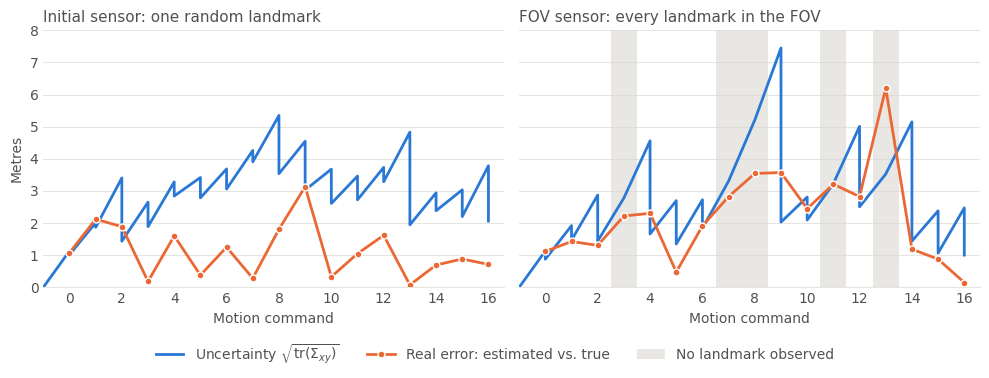

In [17]:
# Position error of the EKF and its uncertainty along the run: the correction shows up as a vertical drop
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
titles = {'one_landmark': 'Initial sensor: one random landmark', 'landmarks_in_fov': 'FOV sensor: every landmark in the FOV'}
COLOR_SIGMA, COLOR_ERROR, GRID, INK = '#2a78d6', '#eb6834', '#e6e5e0', '#52514e'

for ax, (mode, log) in zip(axes, runs.items()):
    steps = np.arange(len(log['n']))
    # Sawtooth: from the previous estimate up to the prediction, then down to the new estimate
    x_saw, y_saw = [-1], [0.]
    for k in steps:
        x_saw += [k, k]
        y_saw += [log['s_pred'][k], log['s_est'][k]]
    for k in steps[log['n'] == 0]:
        ax.axvspan(k-.5, k+.5, color='#d9d8d2', alpha=.6, linewidth=0, label='No landmark observed' if k == steps[log['n'] == 0][0] else None)
    ax.plot(x_saw, y_saw, color=COLOR_SIGMA, linewidth=2, label=r'Uncertainty $\sqrt{\mathrm{tr}(\Sigma_{xy})}$')
    ax.plot(steps, log['e_est'], color=COLOR_ERROR, linewidth=2, marker='o', markersize=5,
            markeredgecolor='white', markeredgewidth=1, label='Real error: estimated vs. true')
    ax.set_title(titles[mode], fontsize=11, color=INK, loc='left')
    ax.set_xlabel('Motion command', color=INK)
    ax.set_xticks(range(0, 17, 2))
    ax.set_xlim(-1, 16.6)
    ax.set_ylim(0, 8)
    ax.grid(axis='y', color=GRID, linewidth=.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK, length=0)
    for side in ('top', 'right', 'left'):
        ax.spines[side].set_visible(False)
    ax.spines['bottom'].set_color(GRID)

axes[0].set_ylabel('Metres', color=INK)
handles, labels = axes[1].get_legend_handles_labels()
order = [labels.index(l) for l in labels if not l.startswith('No')] + [labels.index('No landmark observed')]
fig.legend([handles[i] for i in order], [labels[i] for i in order], loc='lower center', ncol=3, frameon=False, labelcolor=INK)
fig.tight_layout(rect=(0, .09, 1, 1))
plt.close(fig)
display(fig)


**Observaciones del experimento:**

- **El diente de sierra es el ciclo del EKF.** Cada subida es una predicción ($\bar\Sigma_t = G_t\Sigma_{t-1}G_t^T + R_t$) y cada caída, una corrección. Donde no se ve ningún landmark (bandas grises) no hay caída y la incertidumbre se acumula.
- **La incertidumbre es creíble.** El error real suele quedar por debajo de $\sqrt{\mathrm{tr}(\Sigma_{xy})}$ y rara vez supera el doble (última columna de la tabla de 200 semillas). El caso más llamativo es el paso 13 con el sensor FOV: sin ningún landmark a la vista el error llega a 6.2 m, y al ver 3 en el paso 14 cae a 1.2 m.
- **Una sola ejecución no basta para comparar sensores**, porque cada uno gasta números aleatorios distintos y el robot real sigue otro camino. Por eso se promedia sobre 200 semillas: el error ideal-real final es prácticamente el mismo (no depende del sensor), mientras que el error del filtro es mayor con el sensor FOV.

### <font color="blue"><b><i>Thinking about it (1)</i></b></font>

Having completed the EKF implementation, you are ready to **answer the following questions**:

- What are the dimensions of the Jacobians of the observation model (matrix $H_t$)?  Why?

    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i><b>H<sub>t</sub> tiene dimensiones (2n &times; 3)</b>, con n el número de landmarks observados en ese instante. Cada observación aporta 2 filas, porque mide 2 cosas (distancia y marcación), y hay 3 columnas porque se deriva respecto a las 3 variables de la pose (x, y, &theta;). Con el sensor inicial n = 1 siempre, así que H es 2&times;3. Con el sensor FOV, n cambia en cada paso: en la ejecución del notebook va de 0 a 4 (H de 8&times;3 como máximo). Estas dimensiones son las que hacen encajar la ganancia: H &Sigma;&#772; H<sup>T</sup> + Q<sub>t</sub> es 2n&times;2n y K es 3&times;2n, que convierte una innovación de 2n filas en una corrección de la pose de 3 filas.</i></p>

- Discuss the evolution of the ideal, true and estimated poses when executing the EKF filter (with the initial sensor).

    <div style="margin: 4px 0px 6px 5px; color:#2DD4BF; font-style: italic"><ul><li><b>Pose ideal (rojo):</b> sigue el cuadrado perfecto, porque solo compone los comandos sin ruido. No sabe nada de lo que le pasa de verdad al robot.</li><li><b>Pose real (azul):</b> se aleja cada vez más de la ideal, porque el ruido se acumula y cada error de orientación desvía todos los movimientos siguientes. La distancia entre ambas pasa de 1.26 m en el primer paso a 41.64 m en el paso 14 (39.24 m al final).</li><li><b>Pose estimada (verde):</b> se mantiene pegada a la real aunque esta se haya ido muy lejos de la ideal: el error medio es de 1.12 m y el máximo, de 3.13 m. El filtro no se fía del comando, sino que corrige con los landmarks del mapa, que son una referencia absoluta.</li><li><b>Incertidumbre (elipse verde):</b> crece en cada predicción y se reduce en cada corrección, sin dispararse: &radic;tr(&Sigma;<sub>xy</sub>) llega a 5.35 m tras predecir y se queda entre 1.01 y 3.91 m tras corregir. Las elipses salen alargadas en perpendicular a la última línea magenta: la distancia es precisa (&sigma; = 1 m), pero la marcación no (&sigma; = 0.7 rad, unos 40&deg;, es decir, unos 21 m de error lateral a 30 m). Por eso una sola observación corrige sobre todo a lo largo del rayo.</li></ul></div>

- Discuss the evolution of the ideal, true and estimated poses when executing the EKF filter (with the sensor implementing a FOV). Pay special attention to their associated uncertainties.

    <div style="margin: 4px 0px 6px 5px; color:#2DD4BF; font-style: italic"><ul><li><b>Pose ideal (rojo):</b> igual que antes, el cuadrado sin ruido.</li><li><b>Pose real (azul):</b> también se separa de la ideal. En esta ejecución acaba a 15.72 m, pero eso no significa que este sensor la acerque: la pose real no depende del sensor, y con 200 semillas la separación final media es la misma, 19.98 m con el sensor inicial y 19.67 m con el FOV.</li><li><b>Pose estimada (verde):</b> sigue a la real, pero peor y de forma más irregular: error medio de 2.21 m, con un máximo de 6.20 m en el paso 13, frente a 1.12 y 3.13 m antes. Con 200 semillas, 2.86 m frente a 1.88 m.</li><li><b>Incertidumbre:</b> es lo más distinto. Ahora depende de cuántos landmarks entran en el FOV. En 5 de los 17 pasos (3, 7, 8, 11 y 13) no se ve ninguno y la elipse crece sin corrección: &radic;tr(&Sigma;<sub>xy</sub>) pasa de 3.31 a 5.21 m en los pasos 7 y 8 y llega a 7.45 m en la predicción del paso 9, donde un solo landmark la baja a 2.03 m. En cambio, con varios landmarks a la vez la elipse es la más pequeña de toda la ejecución (0.87 m con 3 landmarks; 1.00 m con 4), porque se observa desde varias direcciones y cada una limita lo que la otra deja libre.</li></ul>El sensor FOV es peor de media porque en el 26 % de los pasos no ve nada, pero es el realista, y el filtro refleja bien esa pérdida de información en el tamaño de la elipse.</div>

- What happens in the EKF filter when the robot performs a motion command, but it is unable to measure distances to any landmark, i.e. they are out of the sensor FOV?

    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Solo se hace la <b>predicción</b>. Sin landmarks, <code>landmark.shape[0]</code> vale 0, se salta la corrección y <code>xEst = xPred</code>, <code>PEst = PPred</code>. El filtro no falla (no hay que resolver ningún sistema, como sí pasa con mínimos cuadrados), pero trabaja a ciegas: la pose se mueve solo con el comando y la incertidumbre crece, porque &Sigma;&#772;<sub>t</sub> = G<sub>t</sub> &Sigma;<sub>t-1</sub> G<sub>t</sub><sup>T</sup> + R<sub>t</sub> nunca resta. Es la odometría del tema 3. Lo he comprobado con un sensor de alcance 0, que nunca ve nada: &radic;tr(&Sigma;<sub>xy</sub>) sube de 1.13 a 23.03 m en 17 pasos y la estimación coincide exactamente con la pose ideal, con 15.72 m de error real al final. Cuando el robot vuelve a ver un landmark, &Sigma;&#772;<sub>t</sub> es grande, por lo que K también lo es y la corrección es fuerte: es lo que ocurre en el paso 9 de la ejecución (de 7.45 a 2.03 m).</i></p>

## <font color="orange"><b><i>AI Appendix</i></b></font>

### A.1 How I used AI
- **Model/tool:**
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Un asistente de programación basado en IA generativa (Claude Code con Claude Opus 5.5).</i></p>
- **What I asked AI to help with (bullets):**
  <div style="margin: 4px 0px 6px 5px; color:#2DD4BF; font-style: italic"><ul><li>Completar <code>Sensor</code>, <code>Robot.step()</code>, <code>getObsJac()</code>, <code>EKFLocalization()</code> y <code>FOVSensor.observe_in_fov()</code>, y comprobarlos con las salidas esperadas.</li><li>Añadir una comprobación del jacobiano con derivadas numéricas y un ejemplo de por qué hay que normalizar la marcación de la innovación.</li><li>Un experimento que registra error e incertidumbre paso a paso con los dos sensores, y su promedio sobre 200 semillas.</li><li>Redactar las respuestas de <i>Thinking about it</i> a partir de esos números.</li></ul></div>
- **Best prompt I used (paste):**
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"></p>
- **What I kept vs. changed from the AI output:**
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>He mantenido el código porque reproduce todas las salidas esperadas del enunciado y el jacobiano coincide con el numérico. Respecto a la plantilla, la corrección necesitaba más líneas de las previstas: la matriz Q<sub>t</sub> por bloques y la innovación aparte, normalizando la marcación, porque una resta de ángulos puede salirse de [-&pi;, &pi;]. No me quedé con la primera comparación entre sensores, hecha con una sola ejecución: parecía que el sensor FOV acercaba la pose real a la ideal (15.72 m frente a 39.24 m), pero con 200 semillas la diferencia desaparece (19.67 y 19.98 m), así que ese dato se debía a la semilla. También añadí <code>plt.close('all')</code> tras la primera ejecución de <code>main()</code>, porque dejaba una figura en blanco en el documento.</i></p>

### A.2 AI review
Ask one generative AI to review your memo using this prompt:

```
Act as a technical reviewer of this robotics notebook. Read my memo and return exactly 5 bullet points:

- two on theory (key ideas),
- two on practice (relevant programming concepts of python used, not particular functions or variables),
- one on how to improve the code (most critical aspect: limitations, parameter choices, runtime/robustness, possible bugs).

Keep each bullet ≤15 words and make them specific to my work.
```

Paste its **5** items here:

*AI used for the review: the same AI assistant (Claude Code with Claude Opus 5.5).*

- **(Theory 1)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>El EKF alterna predicción, que aumenta Σ, y corrección, que la reduce según K.</i></p>
- **(Theory 2)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>H apila bloques 2×3: con n landmarks, innovación y Q<sub>t</sub> pasan a dimensión 2n.</i></p>
- **(Practice 1)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>El broadcasting y el slicing con paso tratan varios landmarks a la vez sin bucles.</i></p>
- **(Practice 2)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Herencia: FOVSensor reutiliza observe() de Sensor y añade solo el filtrado por campo de visión.</i></p>
- **(Improvement)** AI claim:
  <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>La asociación de datos es perfecta; falta validar cada observación con la distancia de Mahalanobis.</i></p>

Finally, **do you agree with them?**, **would you have selected others?**
    <p style="margin: 4px 0px 6px 5px; color:#2DD4BF"><i>Estoy de acuerdo con los cinco puntos. Los teóricos resumen lo que se ve en la figura de incertidumbre, y la mejora es la más importante: el simulador entrega al filtro el índice exacto de cada landmark, mientras que un robot real tendría que averiguarlo, y una sola asociación errónea movería la pose sin que el filtro lo detectara. Habría añadido dos mejoras concretas del código: <code>np.sqrt(self.cov)</code> saca la raíz elemento a elemento, lo que solo es válido con covarianzas diagonales (en general habría que usar Cholesky), y sería más robusto numéricamente usar <code>linalg.solve</code> en lugar de <code>linalg.inv</code> para la ganancia.</i></p>